# **Option Pricing & Risk Library**
A small Python project that prices European options with Black-Scholes and Monte Carlo, computes Greeks, and recovers implied volatility. Every part is checked with tests.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

## **Black-Scholes**
Closed-form price and Greeks (delta, gamma, vega) for European calls and puts with a continuous dividend yield.

In [10]:
def d1_d2(S, K, T, r, sigma, q=0.0):
    d1 = (np.log(S/K) + (r - q + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    return d1, d1 - sigma*np.sqrt(T)

def bs_price(S, K, T, r, sigma, q=0.0, kind="call"):
    d1, d2 = d1_d2(S, K, T, r, sigma, q)
    if kind == "call":
        return S*np.exp(-q*T)*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
    return K*np.exp(-r*T)*norm.cdf(-d2) - S*np.exp(-q*T)*norm.cdf(-d1)

def bs_greeks(S, K, T, r, sigma, q=0.0, kind="call"):
    d1, _ = d1_d2(S, K, T, r, sigma, q)
    delta = np.exp(-q*T) * (norm.cdf(d1) if kind == "call" else norm.cdf(d1) - 1)
    gamma = np.exp(-q*T) * norm.pdf(d1) / (S*sigma*np.sqrt(T))
    vega  = S*np.exp(-q*T) * norm.pdf(d1) * np.sqrt(T)
    return {"delta": delta, "gamma": gamma, "vega": vega}

## **Monte Carlo**
Simulates terminal prices under geometric Brownian motion, using antithetic variates to reduce variance. Returns the price and its standard error.

In [11]:
print(bs_price(100, 100, 1, 0.05, 0.2, kind="call"))   # ~10.4506
print(bs_price(100, 100, 1, 0.05, 0.2, kind="put"))    # ~5.5735
print(bs_greeks(100, 100, 1, 0.05, 0.2))               # delta ~0.6368

10.450583572185565
5.573526022256971
{'delta': np.float64(0.6368306511756191), 'gamma': np.float64(0.018762017345846895), 'vega': np.float64(37.52403469169379)}


In [12]:
def mc_price(S, K, T, r, sigma, q=0.0, kind="call", n=100_000, seed=0):
    rng = np.random.default_rng(seed)
    z = rng.standard_normal(n)
    z = np.concatenate([z, -z])          # antithetic variates
    ST = S*np.exp((r - q - 0.5*sigma**2)*T + sigma*np.sqrt(T)*z)
    payoff = np.maximum(ST - K, 0) if kind == "call" else np.maximum(K - ST, 0)
    disc = np.exp(-r*T) * payoff
    return disc.mean(), disc.std(ddof=1)/np.sqrt(len(disc))

price, se = mc_price(100, 100, 1, 0.05, 0.2)
print(price, "+/-", se)    # should be close to 10.45

10.451231088901308 +/- 0.03294359822045014


### **Convergence**
The error against Black-Scholes should fall as the number of simulated paths grows.

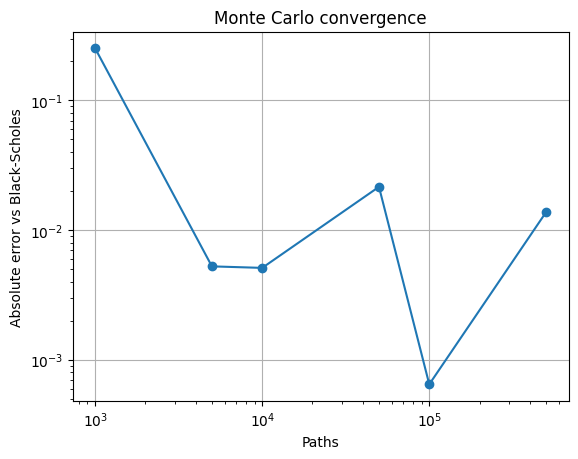

In [13]:
bs = bs_price(100, 100, 1, 0.05, 0.2)
ns = [1_000, 5_000, 10_000, 50_000, 100_000, 500_000]
errs = [abs(mc_price(100, 100, 1, 0.05, 0.2, n=n)[0] - bs) for n in ns]

plt.loglog(ns, errs, marker="o")
plt.xlabel("Paths"); plt.ylabel("Absolute error vs Black-Scholes")
plt.title("Monte Carlo convergence"); plt.grid(True); plt.show()

## **Implied Volatility**
Finds the volatility that makes the Black-Scholes price match a given option price, using Brent's root-finding method.

In [14]:
def implied_vol(price, S, K, T, r, q=0.0, kind="call"):
    return brentq(lambda s: bs_price(S, K, T, r, s, q, kind) - price, 1e-6, 5.0)

p = bs_price(100, 100, 1, 0.05, 0.25)
print(implied_vol(p, 100, 100, 1, 0.05))   # should print 0.25

0.24999999999982547


## **Tests**
Checks that put-call parity holds, Monte Carlo agrees with Black-Scholes within its standard error, analytical delta matches a finite-difference estimate, and implied volatility recovers the input value.

In [15]:
# 1. Put-call parity
c = bs_price(100, 100, 1, 0.03, 0.2, kind="call")
p = bs_price(100, 100, 1, 0.03, 0.2, kind="put")
assert abs(c - p - (100 - 100*np.exp(-0.03))) < 1e-8

# 2. Monte Carlo within 4 standard errors of Black-Scholes
bs = bs_price(100, 105, 1, 0.03, 0.2)
mc, se = mc_price(100, 105, 1, 0.03, 0.2)
assert abs(mc - bs) < 4*se

# 3. Analytical delta matches finite difference
h = 1e-4
fd = (bs_price(100+h, 100, 1, 0.05, 0.2) - bs_price(100-h, 100, 1, 0.05, 0.2)) / (2*h)
assert abs(fd - bs_greeks(100, 100, 1, 0.05, 0.2)["delta"]) < 1e-6

# 4. Implied vol recovers the input volatility
assert abs(implied_vol(bs_price(100, 110, 0.5, 0.02, 0.3), 100, 110, 0.5, 0.02) - 0.3) < 1e-6

print("All tests passed")

All tests passed


## **Greeks**
How the call price, delta and gamma change as the spot price moves.

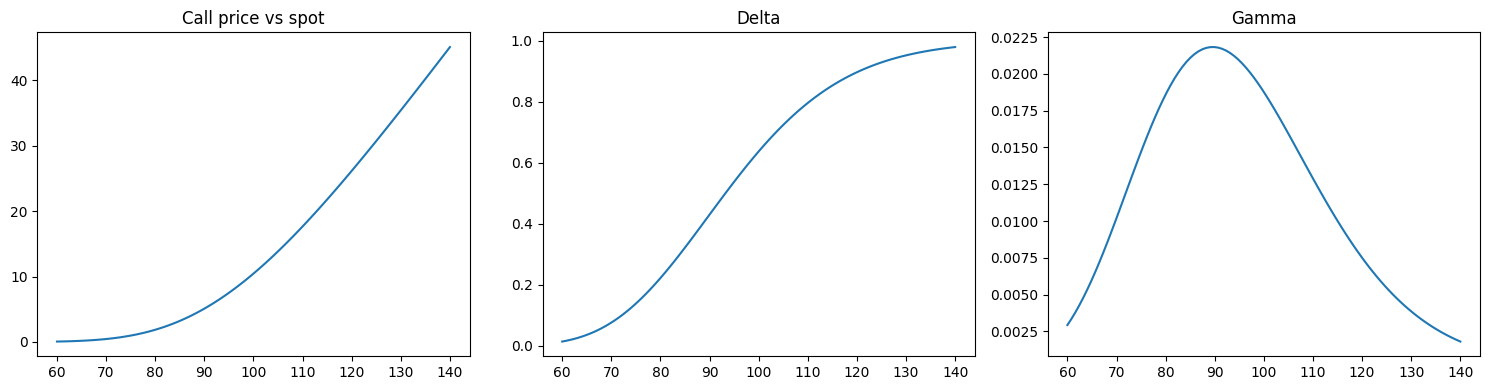

In [16]:
spots = np.linspace(60, 140, 100)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(spots, bs_price(spots, 100, 1, 0.05, 0.2)); ax[0].set_title("Call price vs spot")
ax[1].plot(spots, bs_greeks(spots, 100, 1, 0.05, 0.2)["delta"]); ax[1].set_title("Delta")
ax[2].plot(spots, bs_greeks(spots, 100, 1, 0.05, 0.2)["gamma"]); ax[2].set_title("Gamma")
plt.tight_layout(); plt.show()